**1. Data ingestion**

In [0]:
import pandas as pd
import numpy as np

In [0]:
order_items = spark.read.table("analystlab.default.order_items_2").toPandas()

display(order_items)

order_item_id,created_at,order_id,product_id,is_primary_item,price_usd,cogs_usd
1,3/19/2012 10:42,1,1,1,49.99,19.49
2,3/19/2012 19:27,2,1,1,49.99,19.49
3,3/20/2012 6:44,3,1,1,49.99,19.49
4,3/20/2012 9:41,4,1,1,49.99,19.49
5,3/20/2012 11:28,5,1,1,49.99,19.49
6,3/20/2012 16:12,6,1,1,49.99,19.49
7,3/20/2012 17:03,7,1,1,49.99,19.49
8,3/20/2012 23:35,8,1,1,49.99,19.49
9,3/21/2012 2:35,9,1,1,49.99,19.49
10,3/21/2012 6:45,10,1,1,49.99,19.49


**2. Examine the shape, columns and data types.**

In [0]:
 # 1. Check dataset dimensions
print("Dataset shape:", order_items.shape)

Dataset shape: (40025, 7)


In [0]:
 # 2. Display column names
print("\nDataset columns:")
print(order_items.columns)


Dataset columns:
Index(['order_item_id', 'created_at', 'order_id', 'product_id',
       'is_primary_item', 'price_usd', 'cogs_usd'],
      dtype='object')


In [0]:
 # 3. Check data types and missing values
print("\nDataset information:")
order_items.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40025 entries, 0 to 40024
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_item_id    40025 non-null  int64  
 1   created_at       40025 non-null  object 
 2   order_id         40025 non-null  int64  
 3   product_id       40025 non-null  int64  
 4   is_primary_item  40025 non-null  int64  
 5   price_usd        40025 non-null  float64
 6   cogs_usd         40025 non-null  float64
dtypes: float64(2), int64(4), object(1)
memory usage: 2.1+ MB


In [0]:
 # 4. Display the first 5 records
print("\nFirst 5 records:")
display(order_items.head())


First 5 records:


order_item_id,created_at,order_id,product_id,is_primary_item,price_usd,cogs_usd
1,3/19/2012 10:42,1,1,1,49.99,19.49
2,3/19/2012 19:27,2,1,1,49.99,19.49
3,3/20/2012 6:44,3,1,1,49.99,19.49
4,3/20/2012 9:41,4,1,1,49.99,19.49
5,3/20/2012 11:28,5,1,1,49.99,19.49


**3. Identify missing values and duplicate records.**

In [0]:
 # Check missing values in each column
print("Missing values:")
print(order_items.isnull().sum())

# Check total missing values
print("\nTotal missing values:")
print(order_items.isnull().sum().sum())

# Check duplicate rows
print("\nTotal duplicate rows:")
print(order_items.duplicated().sum())

# Check duplicate order item IDs
print("\nDuplicate order item IDs:")
print(order_items["order_item_id"].duplicated().sum())

Missing values:
order_item_id      0
created_at         0
order_id           0
product_id         0
is_primary_item    0
price_usd          0
cogs_usd           0
dtype: int64

Total missing values:
0

Total duplicate rows:
0

Duplicate order item IDs:
0


**4. Investigate the relationships between the datasets.**

In [0]:
 # Check the first 10 dates
print("Sample dates:")
print(order_items["created_at"].head(10))

# Check the primary item values
print("\nPrimary item values:")
print(order_items["is_primary_item"].value_counts())

# Check price statistics
print("\nPrice summary:")
print(order_items["price_usd"].describe())

# Check cost statistics
print("\nCOGS summary:")
print(order_items["cogs_usd"].describe())

Sample dates:
0    3/19/2012 10:42
1    3/19/2012 19:27
2     3/20/2012 6:44
3     3/20/2012 9:41
4    3/20/2012 11:28
5    3/20/2012 16:12
6    3/20/2012 17:03
7    3/20/2012 23:35
8     3/21/2012 2:35
9     3/21/2012 6:45
Name: created_at, dtype: object

Primary item values:
is_primary_item
1    32313
0     7712
Name: count, dtype: int64

Price summary:
count    40025.000000
mean        48.432473
std          8.012370
min         29.990000
25%         49.990000
50%         49.990000
75%         49.990000
max         59.990000
Name: price_usd, dtype: float64

COGS summary:
count    40025.000000
mean        18.047976
std          3.856821
min          9.490000
25%         19.490000
50%         19.490000
75%         19.490000
max         22.490000
Name: cogs_usd, dtype: float64


In [0]:
 # Convert created_at from text to datetime
order_items["created_at"] = pd.to_datetime(
    order_items["created_at"],
    format="%m/%d/%Y %H:%M"
)

# Check the updated data types
print(order_items.dtypes)

# Display the first 5 dates
print("\nUpdated dates:")
print(order_items["created_at"].head())

order_item_id               int64
created_at         datetime64[ns]
order_id                    int64
product_id                  int64
is_primary_item             int64
price_usd                 float64
cogs_usd                  float64
dtype: object

Updated dates:
0   2012-03-19 10:42:00
1   2012-03-19 19:27:00
2   2012-03-20 06:44:00
3   2012-03-20 09:41:00
4   2012-03-20 11:28:00
Name: created_at, dtype: datetime64[ns]


In [0]:
 # Check for zero or negative selling prices
print("Invalid selling prices:")
print((order_items["price_usd"] <= 0).sum())

# Check for zero or negative costs
print("\nInvalid COGS:")
print((order_items["cogs_usd"] <= 0).sum())

# Check primary item values
print("\nPrimary item categories:")
print(order_items["is_primary_item"].unique())

# Check for missing dates after conversion
print("\nMissing dates:")
print(order_items["created_at"].isna().sum())

Invalid selling prices:
0

Invalid COGS:
0

Primary item categories:
[1 0]

Missing dates:
0


In [0]:
 # Calculate gross profit for each order item
order_items["gross_profit"] = (
    order_items["price_usd"] - order_items["cogs_usd"]
)

# Calculate profit margin as a percentage
order_items["profit_margin"] = (
    order_items["gross_profit"] / order_items["price_usd"]
) * 100

# Display the first 5 records
display(order_items.head())

# Summarise the new columns
print("\nGross profit summary:")
print(order_items["gross_profit"].describe())

print("\nProfit margin summary:")
print(order_items["profit_margin"].describe())

order_item_id,created_at,order_id,product_id,is_primary_item,price_usd,cogs_usd,gross_profit,profit_margin
1,2012-03-19T10:42:00.000Z,1,1,1,49.99,19.49,30.500000000000004,61.0122024404881
2,2012-03-19T19:27:00.000Z,2,1,1,49.99,19.49,30.500000000000004,61.0122024404881
3,2012-03-20T06:44:00.000Z,3,1,1,49.99,19.49,30.500000000000004,61.0122024404881
4,2012-03-20T09:41:00.000Z,4,1,1,49.99,19.49,30.500000000000004,61.0122024404881
5,2012-03-20T11:28:00.000Z,5,1,1,49.99,19.49,30.500000000000004,61.0122024404881



Gross profit summary:
count    40025.000000
mean        30.384497
std          4.443482
min         20.500000
25%         30.500000
50%         30.500000
75%         31.500000
max         37.500000
Name: gross_profit, dtype: float64

Profit margin summary:
count    40025.000000
mean        63.081608
std          3.126462
min         61.012202
25%         61.012202
50%         61.012202
75%         62.510418
max         68.493151
Name: profit_margin, dtype: float64


In [0]:
%pip install seaborn

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


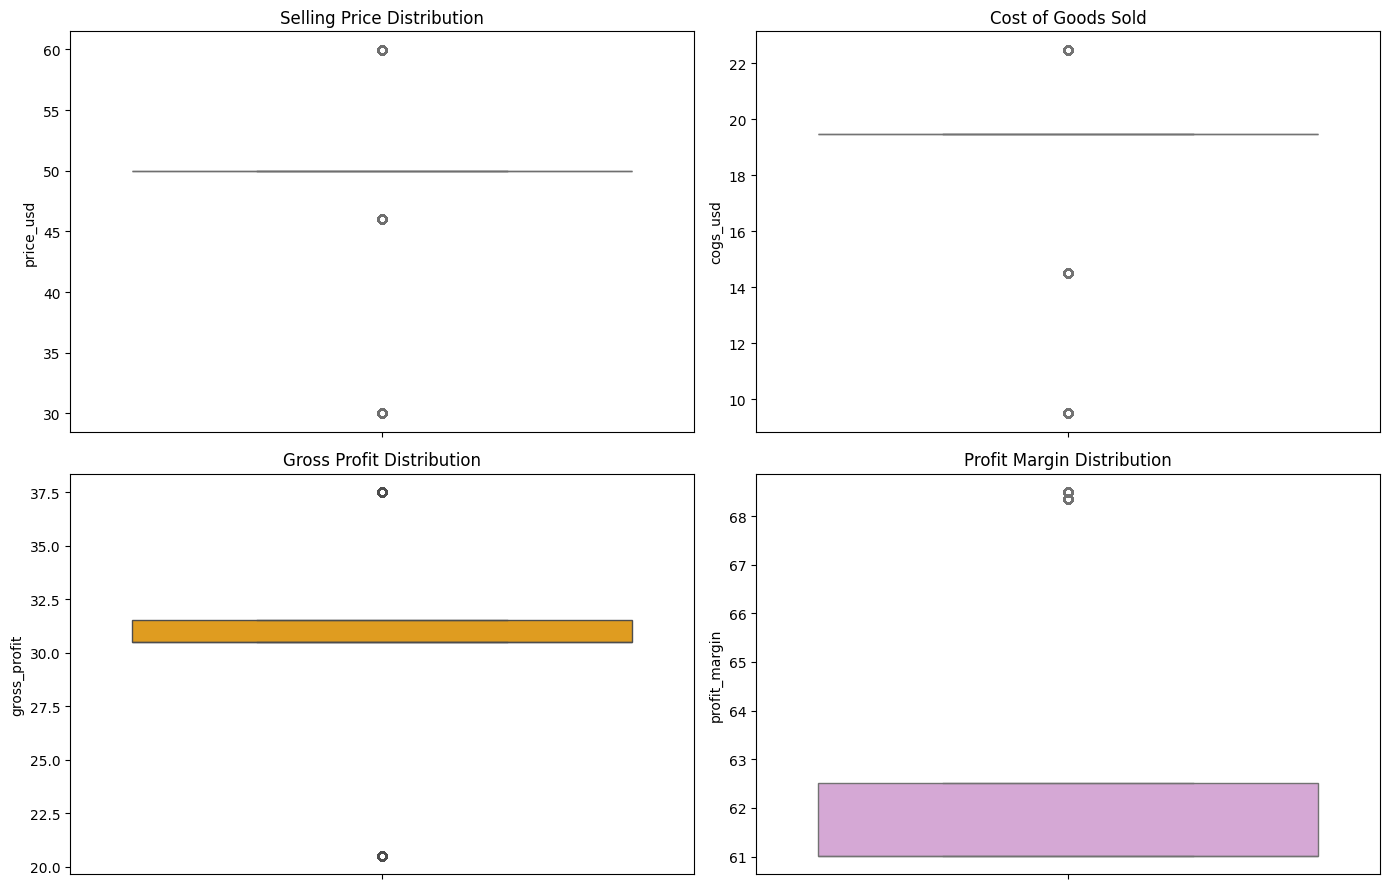

In [0]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a figure with 4 boxplots
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# Selling price
sns.boxplot(data=order_items, y="price_usd", ax=axes[0, 0], color="skyblue")
axes[0, 0].set_title("Selling Price Distribution")

# Cost of goods sold
sns.boxplot(data=order_items, y="cogs_usd", ax=axes[0, 1], color="lightgreen")
axes[0, 1].set_title("Cost of Goods Sold")

# Gross profit
sns.boxplot(data=order_items, y="gross_profit", ax=axes[1, 0], color="orange")
axes[1, 0].set_title("Gross Profit Distribution")

# Profit margin
sns.boxplot(data=order_items, y="profit_margin", ax=axes[1, 1], color="plum")
axes[1, 1].set_title("Profit Margin Distribution")

plt.tight_layout()
plt.show()

In [0]:
 # Count each unique selling price
print("Selling price frequencies:")
print(order_items["price_usd"].value_counts().sort_index())

# Count each unique COGS value
print("\nCOGS frequencies:")
print(order_items["cogs_usd"].value_counts().sort_index())

# Count each unique gross profit
print("\nGross profit frequencies:")
print(order_items["gross_profit"].value_counts().sort_index())

Selling price frequencies:
price_usd
29.99     5018
45.99     4985
49.99    24226
59.99     5796
Name: count, dtype: int64

COGS frequencies:
cogs_usd
9.49      5018
14.49     4985
19.49    24226
22.49     5796
Name: count, dtype: int64

Gross profit frequencies:
gross_profit
20.5     5018
30.5    24226
31.5     4985
37.5     5796
Name: count, dtype: int64


In [0]:
 # Group the data by product
product_check = order_items.groupby("product_id").agg(
    selling_price_types=("price_usd", "nunique"),
    cogs_types=("cogs_usd", "nunique"),
    primary_item_types=("is_primary_item", "nunique")
)

# Display the results
print(product_check)

# Check whether any product has multiple prices or costs
print("\nProducts with multiple selling prices:")
print((product_check["selling_price_types"] > 1).sum())

print("\nProducts with multiple COGS values:")
print((product_check["cogs_types"] > 1).sum())

            selling_price_types  cogs_types  primary_item_types
product_id                                                     
1                             1           1                   2
2                             1           1                   2
3                             1           1                   2
4                             1           1                   2

Products with multiple selling prices:
0

Products with multiple COGS values:
0


In [0]:
 # Count primary items in each order
primary_per_order = order_items.groupby("order_id")[
    "is_primary_item"
].sum()

# Summarise the results
print("Number of orders:", order_items["order_id"].nunique())

print("\nPrimary items per order:")
print(primary_per_order.value_counts().sort_index())

# Check orders without a primary item
print("\nOrders without a primary item:")
print((primary_per_order == 0).sum())

# Check orders with more than one primary item
print("\nOrders with multiple primary items:")
print((primary_per_order > 1).sum())

Number of orders: 32313

Primary items per order:
is_primary_item
1    32313
Name: count, dtype: int64

Orders without a primary item:
0

Orders with multiple primary items:
0


In [0]:
 # Extract the year
order_items["year"] = order_items["created_at"].dt.year

# Extract the month
order_items["month"] = order_items["created_at"].dt.month

# Extract the month name
order_items["month_name"] = order_items["created_at"].dt.month_name()

# Extract the day of the week
order_items["day_of_week"] = order_items["created_at"].dt.day_name()

# Create a year-month column
order_items["year_month"] = (
    order_items["created_at"].dt.to_period("M").astype(str)
)

# Display the updated dataset
display(order_items.head())

order_item_id,created_at,order_id,product_id,is_primary_item,price_usd,cogs_usd,year,month,month_name,day_of_week,year_month
1,2012-03-19T10:42:00.000Z,1,1,1,49.99,19.49,2012,3,March,Monday,2012-03
2,2012-03-19T19:27:00.000Z,2,1,1,49.99,19.49,2012,3,March,Monday,2012-03
3,2012-03-20T06:44:00.000Z,3,1,1,49.99,19.49,2012,3,March,Tuesday,2012-03
4,2012-03-20T09:41:00.000Z,4,1,1,49.99,19.49,2012,3,March,Tuesday,2012-03
5,2012-03-20T11:28:00.000Z,5,1,1,49.99,19.49,2012,3,March,Tuesday,2012-03


In [0]:
 # Display all column names
print("Updated dataset columns:")
print(order_items.columns.tolist())

# Display only the new date columns
display(
    order_items[
        ["created_at", "year", "month",
         "month_name", "day_of_week", "year_month"]
    ].head(10)
)

# Check for missing values in the new columns
print("\nMissing values in new columns:")
print(
    order_items[
        ["year", "month", "month_name",
         "day_of_week", "year_month"]
    ].isnull().sum()
)

Updated dataset columns:
['order_item_id', 'created_at', 'order_id', 'product_id', 'is_primary_item', 'price_usd', 'cogs_usd', 'year', 'month', 'month_name', 'day_of_week', 'year_month']


created_at,year,month,month_name,day_of_week,year_month
2012-03-19T10:42:00.000Z,2012,3,March,Monday,2012-03
2012-03-19T19:27:00.000Z,2012,3,March,Monday,2012-03
2012-03-20T06:44:00.000Z,2012,3,March,Tuesday,2012-03
2012-03-20T09:41:00.000Z,2012,3,March,Tuesday,2012-03
2012-03-20T11:28:00.000Z,2012,3,March,Tuesday,2012-03
2012-03-20T16:12:00.000Z,2012,3,March,Tuesday,2012-03
2012-03-20T17:03:00.000Z,2012,3,March,Tuesday,2012-03
2012-03-20T23:35:00.000Z,2012,3,March,Tuesday,2012-03
2012-03-21T02:35:00.000Z,2012,3,March,Wednesday,2012-03
2012-03-21T06:45:00.000Z,2012,3,March,Wednesday,2012-03



Missing values in new columns:
year           0
month          0
month_name     0
day_of_week    0
year_month     0
dtype: int64


In [0]:
 # Check final dataset dimensions
print("Final dataset shape:", order_items.shape)

# Check data types
print("\nFinal data types:")
print(order_items.dtypes)

# Check for missing values
print("\nTotal missing values:")
print(order_items.isnull().sum().sum())

# Check for duplicate records
print("\nTotal duplicate records:")
print(order_items.duplicated().sum())

# Display the final dataset
display(order_items.head())

Final dataset shape: (40025, 12)

Final data types:
order_item_id               int64
created_at         datetime64[ns]
order_id                    int64
product_id                  int64
is_primary_item             int64
price_usd                 float64
cogs_usd                  float64
year                        int32
month                       int32
month_name                 object
day_of_week                object
year_month                 object
dtype: object

Total missing values:
0

Total duplicate records:
0


order_item_id,created_at,order_id,product_id,is_primary_item,price_usd,cogs_usd,year,month,month_name,day_of_week,year_month
1,2012-03-19T10:42:00.000Z,1,1,1,49.99,19.49,2012,3,March,Monday,2012-03
2,2012-03-19T19:27:00.000Z,2,1,1,49.99,19.49,2012,3,March,Monday,2012-03
3,2012-03-20T06:44:00.000Z,3,1,1,49.99,19.49,2012,3,March,Tuesday,2012-03
4,2012-03-20T09:41:00.000Z,4,1,1,49.99,19.49,2012,3,March,Tuesday,2012-03
5,2012-03-20T11:28:00.000Z,5,1,1,49.99,19.49,2012,3,March,Tuesday,2012-03


**Clean and prepare the data for analysis.**

In [0]:
 # Recreate gross profit
order_items["gross_profit"] = (
    order_items["price_usd"] - order_items["cogs_usd"]
)

# Recreate profit margin
order_items["profit_margin"] = (
    order_items["gross_profit"] / order_items["price_usd"]
) * 100

# Confirm all columns are present
print(order_items.columns.tolist())

# Check final shape
print("\nFinal shape:", order_items.shape)

['order_item_id', 'created_at', 'order_id', 'product_id', 'is_primary_item', 'price_usd', 'cogs_usd', 'year', 'month', 'month_name', 'day_of_week', 'year_month', 'gross_profit', 'profit_margin']

Final shape: (40025, 14)


In [0]:
 # Group order items by product
product_analysis = order_items.groupby("product_id").agg(
    total_items=("order_item_id", "count"),
    total_orders=("order_id", "nunique"),
    total_revenue=("price_usd", "sum"),
    total_cogs=("cogs_usd", "sum"),
    total_gross_profit=("gross_profit", "sum")
)

# Sort products by revenue
product_analysis = product_analysis.sort_values(
    by="total_revenue",
    ascending=False
)

# Display results
display(product_analysis)

total_items,total_orders,total_revenue,total_cogs,total_gross_profit
24226,24226,1211057.74,472164.74,738893.0000000001
5796,5796,347702.04000000004,130352.04,217350.0
4985,4985,229260.15000000002,72232.65,157027.5
5018,5018,150489.81999999998,47620.82,102869.0


Task 2: Exploratory data analysis
Investigate the following:
1. How does revenue change over time?
2. Which products generate the highest sales?
3. What are the patterns in customer purchasing behaviour?
4. Which marketing channels attract the most website sessions?
5. How does website traffic differ between mobile and desktop users?
6. What proportion of website sessions result in orders?
7. Which products have the highest refund activity?
8. Are there noticeable differences between new and returning website sessions

In [0]:
 # Group orders by month and calculate revenue
monthly_revenue = order_items.groupby("year_month").agg(
    total_revenue=("price_usd", "sum"),
    total_orders=("order_id", "nunique")
).reset_index()

# Display the results
display(monthly_revenue.head(10))

year_month,total_revenue,total_orders
2012-03,2999.4,60
2012-04,4949.01,99
2012-05,5398.92,108
2012-06,6998.6,140
2012-07,8448.31,169
2012-08,11397.720000000001,228
2012-09,14347.130000000001,287
2012-10,18546.29,371
2012-11,30893.82,618
2012-12,25294.940000000002,506


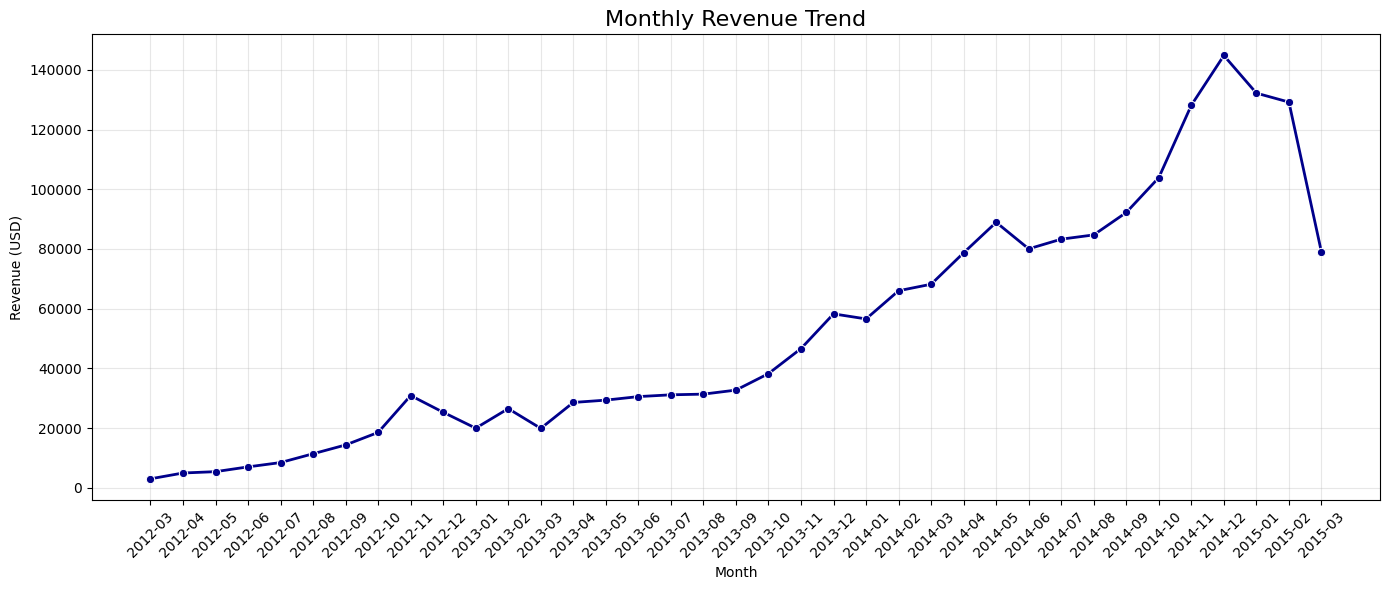

In [0]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_revenue,
    x="year_month",
    y="total_revenue",
    marker="o",
    color="darkblue",
    linewidth=2
)

plt.title("Monthly Revenue Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Revenue (USD)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

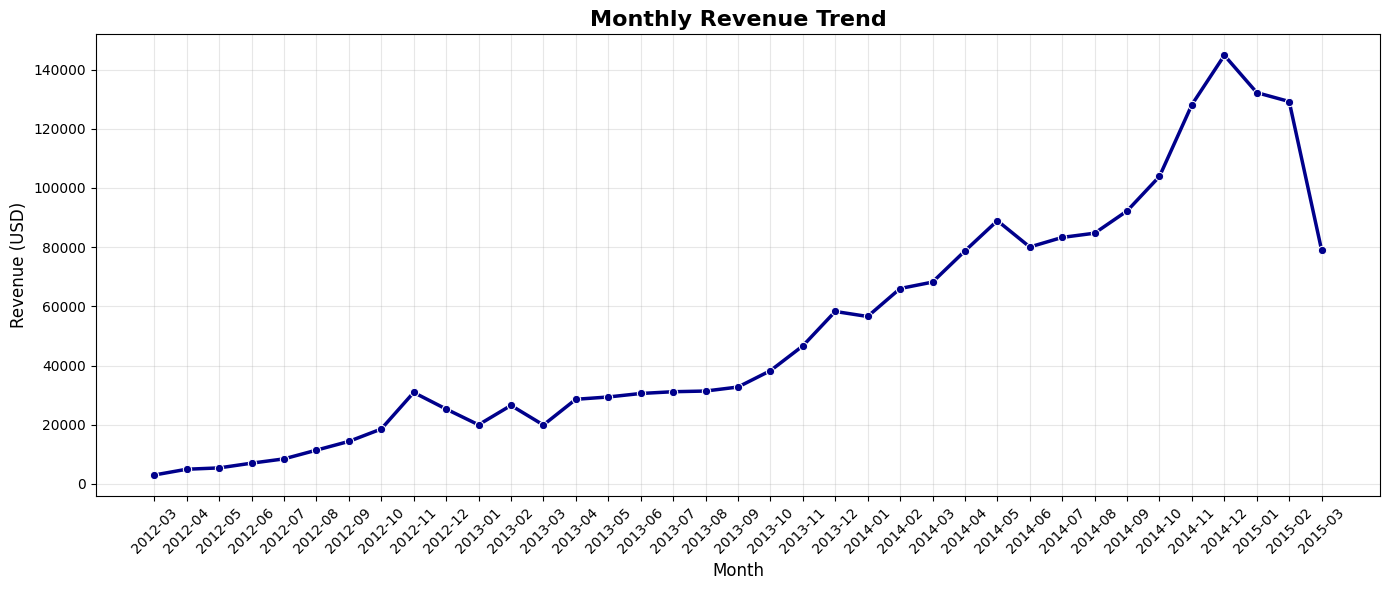

In [0]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_revenue,
    x="year_month",
    y="total_revenue",
    marker="o",
    color="darkblue",
    linewidth=2.5
)

plt.title("Monthly Revenue Trend", fontsize=16, fontweight="bold")
plt.xlabel("Month", fontsize=12)
plt.ylabel("Revenue (USD)", fontsize=12)
plt.xticks(rotation=45)
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [0]:
 #Which products generate the highest sales?
 # Group the data by product and calculate sales
product_sales = order_items.groupby("product_id").agg(
    total_items_sold=("order_item_id", "count"),
    total_revenue=("price_usd", "sum"),
    total_orders=("order_id", "nunique")
).reset_index()

# Arrange products from highest to lowest revenue
product_sales = product_sales.sort_values(
    by="total_revenue",
    ascending=False
)

# Display the results
display(product_sales)

product_id,total_items_sold,total_revenue,total_orders
1,24226,1211057.74,24226
2,5796,347702.04000000004,5796
3,4985,229260.15000000002,4985
4,5018,150489.81999999998,5018


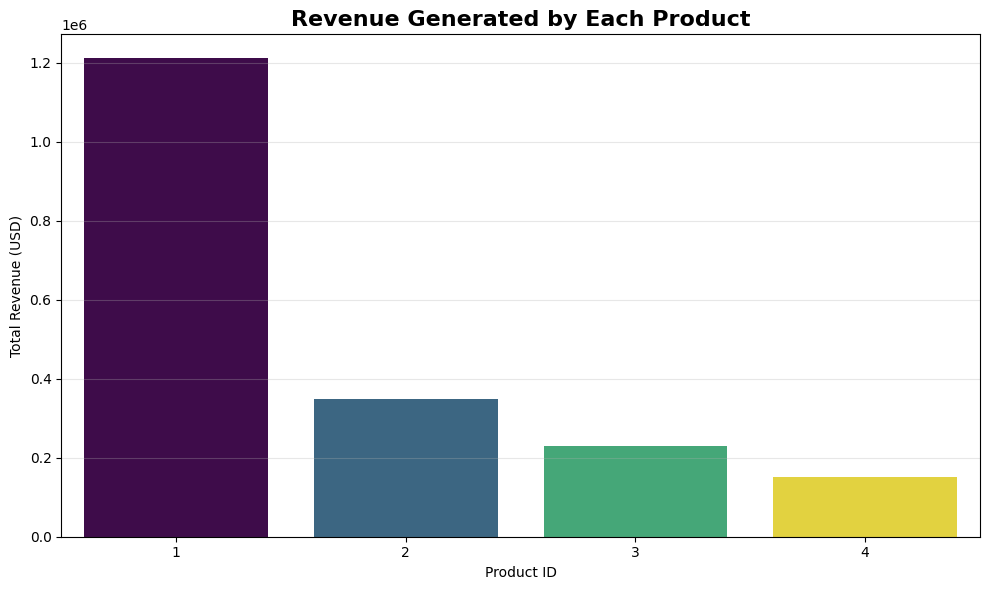

In [0]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=product_sales,
    x="product_id",
    y="total_revenue",
    hue="product_id",
    palette="viridis",
    legend=False
)

plt.title("Revenue Generated by Each Product",
          fontsize=16, fontweight="bold")
plt.xlabel("Product ID")
plt.ylabel("Total Revenue (USD)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

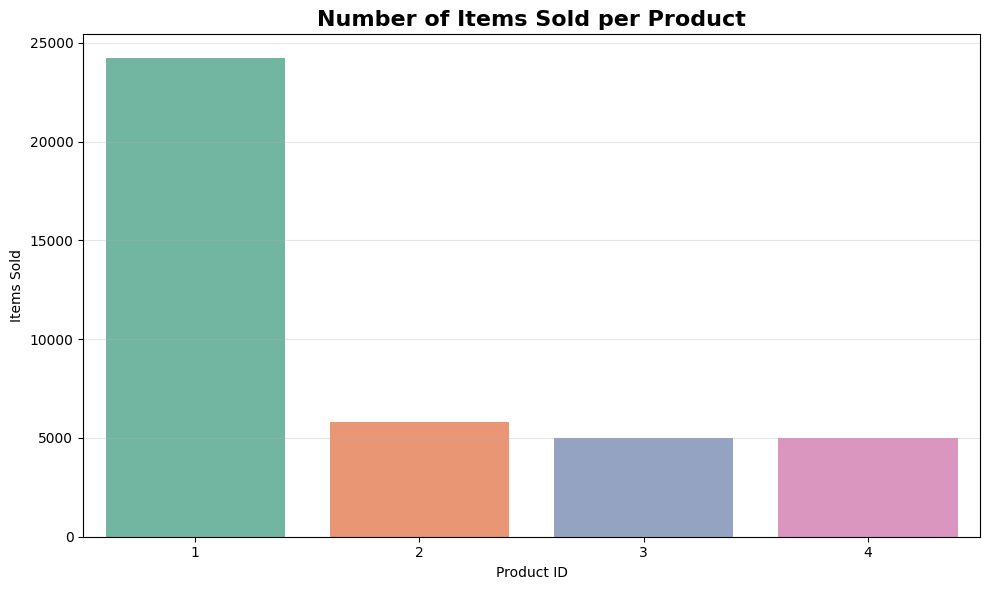

In [0]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=product_sales,
    x="product_id",
    y="total_items_sold",
    hue="product_id",
    palette="Set2",
    legend=False
)

plt.title("Number of Items Sold per Product",
          fontsize=16, fontweight="bold")
plt.xlabel("Product ID")
plt.ylabel("Items Sold")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [0]:
 #What are the patterns in customer purchasing behaviour?
 # Count the number of items in each order
items_per_order = order_items.groupby("order_id").agg(
    items_purchased=("order_item_id", "count"),
    order_value=("price_usd", "sum")
).reset_index()

# Display the first 10 orders
display(items_per_order.head(10))

order_id,items_purchased,order_value
1,1,49.99
2,1,49.99
3,1,49.99
4,1,49.99
5,1,49.99
6,1,49.99
7,1,49.99
8,1,49.99
9,1,49.99
10,1,49.99


In [0]:
 # Summarise the number of items purchased per order
display(items_per_order["items_purchased"].describe())

count    32313.000000
mean         1.238666
std          0.426274
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max          2.000000
Name: items_purchased, dtype: float64

In [0]:
 # Count orders according to the number of items purchased
purchase_frequency = items_per_order["items_purchased"].value_counts().sort_index()

display(purchase_frequency)

items_purchased
1    24601
2     7712
Name: count, dtype: int64

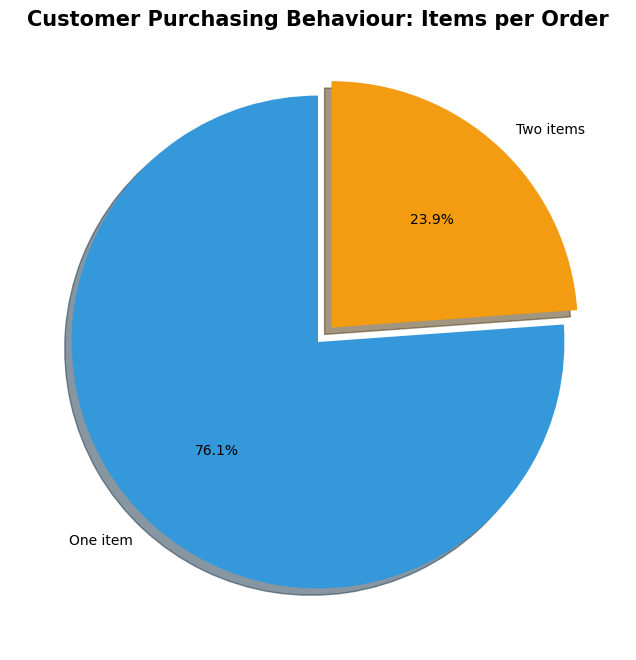

In [0]:
 # Calculate the number of orders for each purchase quantity
purchase_frequency = items_per_order["items_purchased"].value_counts().sort_index()

plt.figure(figsize=(8, 8))

plt.pie(
    purchase_frequency,
    labels=["One item", "Two items"],
    autopct="%1.1f%%",
    startangle=90,
    colors=["#3498DB", "#F39C12"],
    explode=(0, 0.08),
    shadow=True
)

plt.title(
    "Customer Purchasing Behaviour: Items per Order",
    fontsize=15,
    fontweight="bold"
)

plt.show()

Key findings:
1. Customers purchasing two items spend an average of $89.25 per order.
2. Customers purchasing one item spend an average of $50.82.
3. Two-item orders generate approximately 75.6% more revenue per order than one-item orders.
4. Although two-item orders represent only 23.87% of all orders, they contribute a higher average order value.

In [0]:
 # Calculate average order value based on items purchased
order_value_analysis = items_per_order.groupby("items_purchased").agg(
    average_order_value=("order_value", "mean"),
    total_orders=("order_id", "count")
).reset_index()

display(order_value_analysis)

items_purchased,average_order_value,total_orders
1,50.819397178976466,24601
2,89.25074688796681,7712


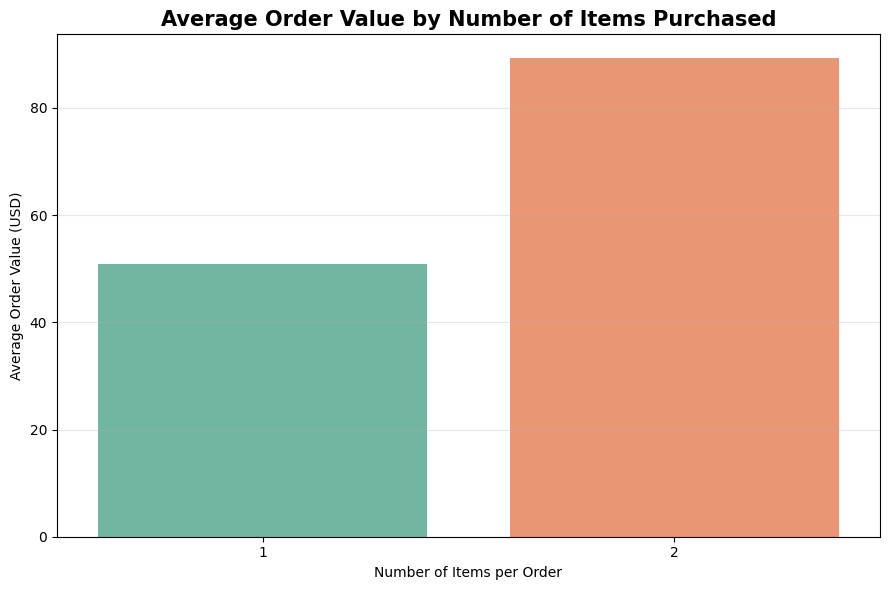

In [0]:
plt.figure(figsize=(9, 6))

sns.barplot(
    data=order_value_analysis,
    x="items_purchased",
    y="average_order_value",
    hue="items_purchased",
    palette="Set2",
    legend=False
)

plt.title("Average Order Value by Number of Items Purchased",
          fontsize=15, fontweight="bold")
plt.xlabel("Number of Items per Order")
plt.ylabel("Average Order Value (USD)")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [0]:
 # Group orders by month
monthly_purchases = order_items.groupby("year_month").agg(
    total_orders=("order_id", "nunique"),
    total_items_sold=("order_item_id", "count"),
    total_revenue=("price_usd", "sum")
).reset_index()

# Display the first 10 months
display(monthly_purchases.head(10))

year_month,total_orders,total_items_sold,total_revenue
2012-03,60,60,2999.4
2012-04,99,99,4949.01
2012-05,108,108,5398.92
2012-06,140,140,6998.6
2012-07,169,169,8448.31
2012-08,228,228,11397.720000000001
2012-09,287,287,14347.130000000001
2012-10,371,371,18546.29
2012-11,618,618,30893.82
2012-12,506,506,25294.940000000002


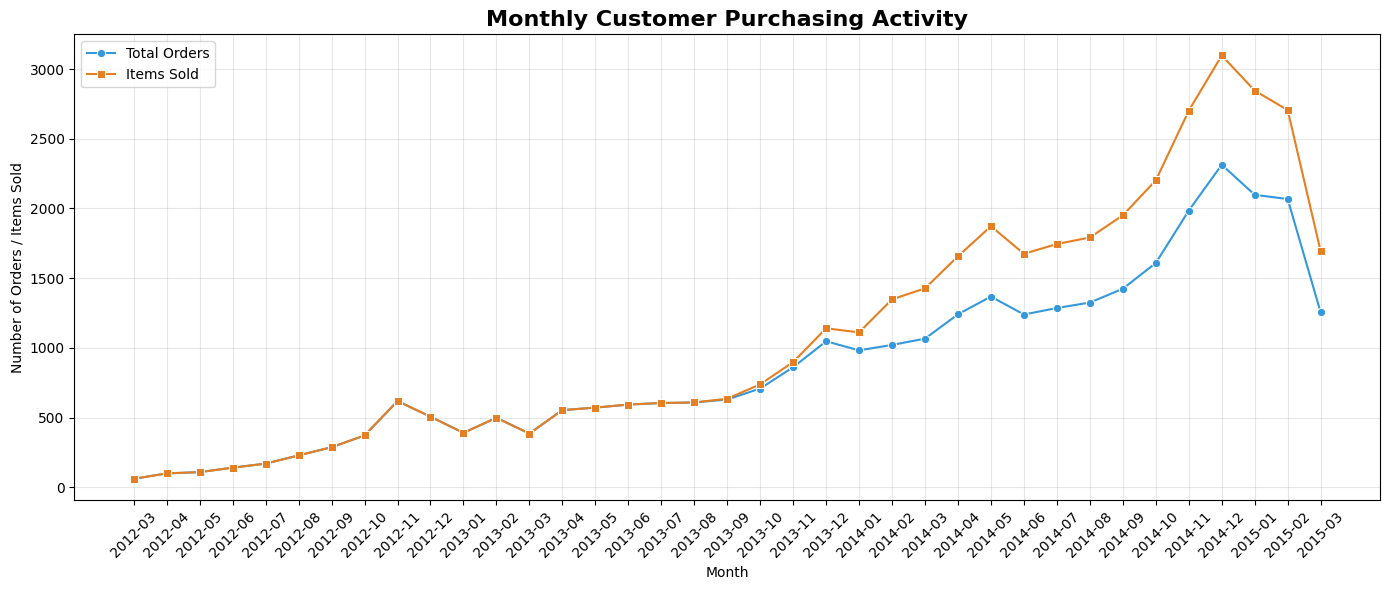

In [0]:
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_purchases,
    x="year_month",
    y="total_orders",
    marker="o",
    label="Total Orders",
    color="#3498DB"
)

sns.lineplot(
    data=monthly_purchases,
    x="year_month",
    y="total_items_sold",
    marker="s",
    label="Items Sold",
    color="#E67E22"
)

plt.title("Monthly Customer Purchasing Activity",
          fontsize=16, fontweight="bold")
plt.xlabel("Month")
plt.ylabel("Number of Orders / Items Sold")
plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [0]:
# Calculate descriptive statistics for orders
orders_statistics = order_items.groupby("order_id").agg(
    items_purchased=("order_item_id", "count"),
    price_usd=("price_usd", "sum"),
    cogs_usd=("cogs_usd", "sum")
).describe()

display(orders_statistics)

items_purchased,price_usd,cogs_usd
32313.0,32313.0,32313.0
1.2386655525639836,59.99163649305233,22.35540649274286
0.42627447732,17.80877104729852,6.238620558926916
1.0,29.99,9.49
1.0,49.99,19.49
1.0,49.99,19.49
1.0,59.99,22.49
2.0,109.98,41.98


In [0]:
 # Calculate descriptive statistics for order items
order_items_statistics = order_items[
    [col for col in ["price_usd", "cogs_usd", "gross_profit", "profit_margin"] if col in order_items.columns]
].describe()

display(order_items_statistics)

price_usd,cogs_usd
40025.0,40025.0
48.432473454091195,18.047976264834478
8.01237018818911,3.856820952704384
29.99,9.49
49.99,19.49
49.99,19.49
49.99,19.49
59.99,22.49


 Task 4: Interpretation and recommendations**

- The analysis indicates that the business has opportunities to improve revenue by focusing on its strongest-selling products and encouraging customers to purchase more items per transaction. Product 1 is the largest revenue contributor, while Product 4 may require further investigation to understand its comparatively lower sales performance. The purchasing analysis also shows that two-item orders have a substantially higher average order value than one-item orders, suggesting that product bundles, cross-selling and checkout recommendations could increase sales.

- The business should also monitor monthly revenue patterns and investigate refund activity to identify potential areas for improvement. Customer engagement could be strengthened through personalised recommendations and follow-up communication. Finally, marketing decisions should be based on conversion rates and revenue generated by each channel, rather than website traffic alone. These recommendations could help the business improve sales performance, encourage repeat purchases and make more effective use of its marketing resources.